In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from plotly.subplots import make_subplots
import sys
import matplotlib.pyplot as plt

geo_notebook_dir = Path.cwd() if Path('utils.py').exists() else Path.cwd() / 'notebooks'
if str(geo_notebook_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(geo_notebook_dir.resolve()))

from utils import (
    audit_city_boundaries,
    city_boundary_map,
)

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
pio.templates.default = 'plotly_white'
pio.renderers.default = 'plotly_mimetype'
colors = {'train': '#2463A6', 'validation': '#DB7B2B'}

In [2]:
data_dir = Path('../data') if Path('../data/train-test.csv').exists() else Path('data')
train_test_df = pd.read_csv(data_dir / 'train-test.csv', parse_dates=['date'])
dec_charts_inputs_df = pd.read_csv(data_dir / 'december-chart-inputs.csv', parse_dates=['date'])
val_pred_template_df = pd.read_csv(data_dir / 'validation-predictions-template.csv')
val_df = pd.read_csv(data_dir / 'validation.csv', parse_dates=['date'])
frames = {'train': train_test_df, 'validation': val_df,
          'december': dec_charts_inputs_df, 'template': val_pred_template_df}
samples = {'train': train_test_df, 'validation': val_df}

display(pd.DataFrame([
    {'dataset': name, 'rows': len(df), 'columns': df.shape[1],
     'date_min': df['date'].min() if 'date' in df else pd.NaT,
     'date_max': df['date'].max() if 'date' in df else pd.NaT}
    for name, df in frames.items()
]).set_index('dataset'))
display(train_test_df.head())

,rows,columns,date_min,date_max
dataset,,,,
train,48000,14,2025-01-01,2025-10-31
validation,12000,13,2025-11-01,2025-12-31
december,31,7,2025-12-01,2025-12-31
template,12000,2,NaT,NaT


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Missing values and descriptive statistics

Empty `predicted_rate` values in the templates are expected and will be filled with predictions. No cleaning or outlier removal is applied at this stage.

In [3]:
missing = pd.concat([
    pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                  'missing_pct': df.isna().mean().mul(100).round(2),
                  'unique': df.nunique()}).rename_axis('column')
    for df in frames.values()
], keys=frames.keys(), names=['dataset', 'column'])
display(missing)
display(pd.DataFrame([
    {'dataset': name, 'duplicate_rows': df.duplicated().sum(),
     'duplicate_load_ids': df['load_id'].duplicated().sum(),
     'negative_weight': df['weight'].lt(0).sum(),
     'nonpositive_distance': df['distance'].le(0).sum()}
    for name, df in samples.items()
]).set_index('dataset'))

display(pd.concat({name: df.select_dtypes('number').describe(percentiles=[.01, .05, .5, .95, .99]).T
                   for name, df in samples.items()},
                  names=['dataset', 'column']).round(3))
display(pd.concat({name: df.select_dtypes('object').drop(columns='load_id').describe().T
                   for name, df in samples.items()}, names=['dataset', 'column']))

dtype  missing  missing_pct  unique
dataset    column                                                      
train      load_id                 object        0         0.00   48000
           pickup                  object        0         0.00      64
           delivery                object        0         0.00      64
           pickup_lat             float64        0         0.00      64
           pickup_lon             float64        0         0.00      63
           delivery_lat           float64        0         0.00      64
           delivery_lon           float64        0         0.00      63
           distance               float64        0         0.00   21204
           equipment               object        0         0.00       3
           weight                 float64      300         0.62   23678
           date            datetime64[ns]        0         0.00     304
           market_index           float64      374         0.78   32884
           quote_signal           float64        0         0.00   37633
           posted_rate            float64        0         0.00   45398
validation load_id                 object        0         0.00   12000
           pickup                  object        0         0.00      72
           delivery                object        0         0.00      72
           pickup_lat             float64        0         0.00      72
           pickup_lon             float64        0         0.00      71
           delivery_lat           float64        0         0.00      72
           delivery_lon           float64        0         0.00      71
           distance               float64        0         0.00    9309
           equipment               object        0         0.00       3
           weight                 float64      165         1.38    9472
           date            datetime64[ns]        0         0.00      61
           market_index           float64      249         2.08    9520
           quote_signal           float64        0         0.00   11117
december   pickup                  object        0         0.00       1
           delivery                object        0         0.00       1
           distance                 int64        0         0.00       1
           equipment               object        0         0.00       1
           weight                   int64        0         0.00       1
           date            datetime64[ns]        0         0.00      31
           predicted_rate         float64       31       100.00       0
template   load_id                 object        0         0.00   12000
           predicted_rate         float64    12000       100.00       0

,duplicate_rows,duplicate_load_ids,negative_weight,nonpositive_distance
dataset,,,,
train,0,0,292,0
validation,0,0,145,0


count       mean        std        min         1%  \
dataset    column                                                              
train      pickup_lat    48000.0     35.648      4.315     28.358     28.358   
           pickup_lon    48000.0    -90.929     13.482   -121.698   -119.795   
           delivery_lat  48000.0     35.641      4.317     28.358     28.358   
           delivery_lon  48000.0    -90.857     13.477   -121.698   -119.795   
           distance      48000.0   1135.857    728.564     70.000    121.899   
           weight        47700.0  31028.844   9391.441 -47500.000   9801.960   
           market_index  47626.0      1.083      0.168      0.676      0.783   
           quote_signal  48000.0      2.062      0.291      0.692      1.305   
           posted_rate   48000.0   2373.981   1486.493     57.220    327.169   
validation pickup_lat    12000.0     35.574      4.367     25.500     28.358   
           pickup_lon    12000.0    -90.725     13.412   -121.698   -119.795   
           delivery_lat  12000.0     35.610      4.352     25.500     28.358   
           delivery_lon  12000.0    -90.914     13.625   -121.698   -119.795   
           distance      12000.0   1141.773    732.334     70.000    119.394   
           weight        11835.0  30506.636  10572.590 -47500.000 -24820.660   
           market_index  11751.0      0.927      0.074      0.724      0.791   
           quote_signal  12000.0      2.051      0.220      1.235      1.542   

                                5%        50%        95%        99%        max  
dataset    column                                                               
train      pickup_lat       28.757     35.295     43.438     44.303     44.303  
           pickup_lon     -116.702    -88.089    -72.181    -69.500    -69.500  
           delivery_lat     28.757     35.295     43.438     44.303     44.303  
           delivery_lon   -116.702    -87.529    -72.181    -69.500    -69.500  
           distance        236.100    953.300   2562.300   3029.304   3439.800  
           weight        17490.950  31436.500  44934.200  47500.000  47500.000  
           market_index      0.836      1.056      1.366      1.407      1.468  
           quote_signal      1.606      2.056      2.551      2.884      3.610  
           posted_rate     599.738   2030.760   4953.766   5972.834  25533.000  
validation pickup_lat       28.757     35.295     43.438     44.303     44.303  
           pickup_lon     -116.702    -87.529    -72.181    -69.500    -69.500  
           delivery_lat     28.757     35.295     43.438     44.303     44.303  
           delivery_lon   -116.702    -87.529    -72.181    -69.500    -69.500  
           distance        234.090    953.600   2592.930   3014.106   3325.700  
           weight        16989.000  31193.000  44650.300  47500.000  47500.000  
           market_index      0.814      0.923      1.041      1.066      1.099  
           quote_signal      1.692      2.051      2.414      2.564      2.896

count unique            top   freq
dataset    column                                       
train      pickup     48000     64  Oklahoma City   1242
           delivery   48000     64      Lexington   1197
           equipment  48000      3        Dry Van  27202
validation pickup     12000     72      Lexington    301
           delivery   12000     72    Bakersfield    299
           equipment  12000      3        Dry Van   6780

## Distributions

Compare train and validation using proportions because their sample sizes differ. Missing values are reported above and excluded from histograms. Negative weights and extreme values are retained.

In [4]:
rate = train_test_df[['posted_rate']].copy()
rate['log10_rate'] = np.log10(rate['posted_rate'].where(rate['posted_rate'].gt(0)))
fig = px.histogram(rate.melt(var_name='scale', value_name='value'), x='value',
                   facet_col='scale', nbins=80, title='Load rate: original and log10 scales',
                   labels={'value': 'Rate (USD) / log10(rate)', 'count': 'Number of loads'})
for trace in fig.data:
    trace.bingroup = trace.xaxis
fig.update_xaxes(matches=None)
fig.update_xaxes(title_text='Load rate, USD', row=1, col=1)
fig.update_xaxes(title_text='log10(load rate)', row=1, col=2)
fig.update_yaxes(matches=None, title_text='Number of loads')
fig.update_layout(height=380, bargap=.05)
fig.show()
display(train_test_df[['posted_rate']].quantile([0, .01, .05, .5, .95, .99, 1]).T)

,0.00,0.01,0.05,0.50,0.95,0.99,1.00
posted_rate,57.22,327.1688,599.7385,2030.76,4953.7665,5972.834,25533.0


In [5]:
eda = pd.concat([df.assign(dataset=name) for name, df in samples.items()], ignore_index=True)
features = [column for column in train_test_df.select_dtypes('number').columns
            if column in val_df.select_dtypes('number').columns]
long = eda.melt(id_vars='dataset', value_vars=features, var_name='feature', value_name='value')
fig = px.histogram(long, x='value', color='dataset', facet_col='feature', facet_col_wrap=2,
                   facet_col_spacing=.14,
                   histnorm='probability', barmode='overlay', opacity=.55, nbins=70,
                   color_discrete_map=colors, title='Numerical features: train vs. validation',
                   labels={'value': 'Value', 'dataset': 'Dataset'})
for trace in fig.data:
    trace.bingroup = trace.xaxis
fig.update_xaxes(matches=None, showticklabels=True)
fig.update_yaxes(matches=None, showticklabels=True, title_text='', tickformat='.0%')
fig.update_yaxes(title_text='Proportion', title_standoff=10, col=1)
fig.update_yaxes(automargin=True)
fig.update_layout(height=280 * ((len(features) + 1) // 2), bargap=.03)
fig.show()

In [6]:
category_freq = pd.concat([
    df[column].value_counts().rename_axis('value').reset_index(name='count')
      .assign(dataset=name, feature=column, share=lambda x: x['count'] / len(df))
    for name, df in samples.items() for column in ['equipment', 'pickup', 'delivery']
], ignore_index=True)
display(category_freq.query("feature == 'equipment'").pivot(
    index='value', columns='dataset', values=['count', 'share']).round(3))
fig = px.bar(category_freq.query("feature == 'equipment'"), x='value', y='share',
             color='dataset', barmode='group', color_discrete_map=colors,
             title='Equipment types', labels={'value': 'Equipment type', 'share': 'Proportion', 'dataset': 'Dataset'})
fig.update_yaxes(tickformat='.0%')
fig.show()

for column in ['pickup', 'delivery']:
    top = train_test_df[column].value_counts().head(15).index
    data = category_freq.query('feature == @column and value in @top')
    fig = px.bar(data, x='value', y='share', color='dataset', barmode='group',
                 category_orders={'value': list(top)}, color_discrete_map=colors,
                 title=f'{column}: 15 most frequent cities in train',
                 labels={'value': 'City', 'share': 'Proportion', 'dataset': 'Dataset'})
    fig.update_yaxes(tickformat='.0%')
    fig.update_layout(xaxis_tickangle=-35)
    fig.show()

display(pd.DataFrame([
    {'column': column,
     'new_validation_values': sorted(set(val_df[column]) - set(train_test_df[column])),
     'validation_rows_with_new_value': (~val_df[column].isin(train_test_df[column])).sum()}
    for column in ['pickup', 'delivery', 'equipment']
]))

count             share           
dataset    train validation  train validation
value                                        
Dry Van  27202.0     6780.0  0.567      0.565
Flatbed   8753.0     2169.0  0.182      0.181
Reefer   12045.0     3051.0  0.251      0.254

,column,new_validation_values,validation_rows_with_new_value
0,pickup,"[Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego]",725
1,delivery,"[Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego]",722
2,equipment,[],0


In [7]:
known_cities = (
    val_df['pickup'].isin(train_test_df['pickup'])
    & val_df['delivery'].isin(train_test_df['delivery'])
)
val_known_cities = val_df.loc[known_cities]
count_samples = {
    'train': train_test_df,
    'validation': val_df,
    'validation: known cities only': val_known_cities,
}
daily = pd.concat([
    df.groupby('date').size().reindex(
        pd.date_range(reference['date'].min(), reference['date'].max(), freq='D'),
        fill_value=0,
    ).rename_axis('date').reset_index(name='loads').assign(dataset=name)
    for name, df in count_samples.items()
    for reference in [train_test_df if name == 'train' else val_df]
], ignore_index=True)
daily['loads_7d'] = daily.groupby('dataset', sort=False)['loads'].transform(
    lambda values: values.rolling(7, center=True, min_periods=7).mean()
)
count_colors = {**colors, 'validation: known cities only': '#238B63'}
fig = px.line(daily, x='date', y='loads', color='dataset',
              color_discrete_map=count_colors,
              title='Daily load counts with centered 7-day moving averages',
              labels={'date': 'Date', 'loads': 'Number of loads', 'dataset': 'Dataset'})
fig.update_traces(line_width=1, opacity=.2, showlegend=False)
for name, group in daily.groupby('dataset', sort=False):
    fig.add_trace(go.Scatter(
        x=group['date'], y=group['loads_7d'], mode='lines',
        name=f'{name} (7-day mean)', legendgroup=name,
        line=dict(color=count_colors[name], width=1.5 if name.endswith('only') else 2.5),
        hovertemplate='%{x|%Y-%m-%d}<br>7-day mean: %{y:.1f}<extra>%{fullData.name}</extra>',
    ))
fig.update_layout(legend=dict(orientation='h', y=-.22, x=0, title_text=''),
                  margin=dict(b=110), hovermode='x unified')
fig.show()
display(daily.groupby('dataset', sort=False)['loads'].agg(
    total_loads='sum', days='size', mean_daily_loads='mean'
).round(2))

,total_loads,days,mean_daily_loads
dataset,,,
train,48000,304,157.89
validation,12000,61,196.72
validation: known cities only,10553,61,173.00


## City map and relative changes in mean daily loads

Validation includes only loads whose pickup and delivery cities appeared in training. Circle area represents the city's share of all training pickup and delivery endpoints: `(pickup count + delivery count) / (2 * training rows)`. Circle color is the sum of pickup and delivery percentage changes in mean daily loads, each calculated as `(validation / train - 1) * 100%`. This sum is not the percentage change of their combined count. Hover shows both components and baseline shares. Equipment remains below the map with its own color scale.

The supplied coordinates differ from real city locations. Map positions use the separate `data/city-coordinates.csv` reference from [GeoNames cities15000](https://download.geonames.org/export/dump/) (CC BY 4.0). Ambiguous names are matched to the largest US city with that name; source records and states are saved in the reference. Original freight inputs are unchanged.

Magenta stars label cities present in validation but absent from all training pickup and delivery locations. Their hover counts use the full validation set. Stars have a fixed size because their training share is zero and percentage growth is undefined.

In [8]:
known_city_mask = (
    val_df['pickup'].isin(train_test_df['pickup'])
    & val_df['delivery'].isin(train_test_df['delivery'])
)
val_known = val_df.loc[known_city_mask]
train_days = pd.date_range(train_test_df['date'].min(), train_test_df['date'].max()).size
val_days = pd.date_range(val_df['date'].min(), val_df['date'].max()).size
cities = sorted(set(train_test_df['pickup']) | set(train_test_df['delivery']))
city_train = pd.DataFrame({
    role.title(): train_test_df[role].value_counts().reindex(cities, fill_value=0) / train_days
    for role in ['pickup', 'delivery']
})
city_val = pd.DataFrame({
    role.title(): val_known[role].value_counts().reindex(cities, fill_value=0) / val_days
    for role in ['pickup', 'delivery']
})
city_change_pct = (city_val.div(city_train.replace(0, np.nan)) - 1) * 100
city_change_pct = city_change_pct.loc[
    city_change_pct.abs().max(axis=1).sort_values(ascending=False).index
]
equipment_means = pd.concat([
    (train_test_df['equipment'].value_counts() / train_days).rename('train'),
    (val_known['equipment'].value_counts() / val_days).rename('validation'),
], axis=1).fillna(0)
equipment_change_pct = (
    (equipment_means['validation'] / equipment_means['train'].replace(0, np.nan) - 1) * 100
).sort_values(ascending=False).to_frame('Change')
city_coordinates = pd.read_csv(data_dir / 'city-coordinates.csv').set_index('city')
map_data = pd.DataFrame(index=city_train.index)
map_data['pickup_share_pct'] = city_train['Pickup'] * train_days / len(train_test_df) * 100
map_data['delivery_share_pct'] = city_train['Delivery'] * train_days / len(train_test_df) * 100
map_data['train_endpoint_share_pct'] = (
    map_data['pickup_share_pct'] + map_data['delivery_share_pct']
) / 2
map_data['pickup_growth_pct'] = city_change_pct['Pickup']
map_data['delivery_growth_pct'] = city_change_pct['Delivery']
map_data['sum_growth_pct'] = map_data['pickup_growth_pct'] + map_data['delivery_growth_pct']
map_data = map_data.join(city_coordinates[['latitude', 'longitude', 'state']], validate='one_to_one')
if map_data[['latitude', 'longitude']].isna().any().any():
    raise ValueError('Missing geographic coordinates for training cities')
map_limit = float(map_data['sum_growth_pct'].abs().max())
equipment_limit = float(equipment_change_pct.abs().to_numpy().max())
size_ref = 2 * map_data['train_endpoint_share_pct'].max() / 20 ** 2
fig = make_subplots(rows=2, cols=1, specs=[[{'type': 'geo'}], [{'type': 'xy'}]],
                    row_heights=[.8, .2], vertical_spacing=.12,
                    subplot_titles=['Cities: size = train endpoint share; color = pickup + delivery growth',
                                    'Equipment: relative change in mean daily loads'])
fig.add_trace(go.Scattergeo(
    lat=map_data['latitude'], lon=map_data['longitude'], mode='markers',
    text=list(map_data.index), showlegend=False,
    marker=dict(size=map_data['train_endpoint_share_pct'], sizemode='area',
                sizeref=size_ref, sizemin=2, color=map_data['sum_growth_pct'],
                coloraxis='coloraxis', opacity=.85, line=dict(color='white', width=.7)),
    customdata=map_data[['state', 'train_endpoint_share_pct', 'pickup_share_pct',
                         'delivery_share_pct', 'pickup_growth_pct', 'delivery_growth_pct',
                         'sum_growth_pct']].to_numpy(),
    hovertemplate='<b>%{text}, %{customdata[0]}</b>'
                  '<br>Train endpoint share: %{customdata[1]:.2f}%'
                  '<br>Train pickup share: %{customdata[2]:.2f}%'
                  '<br>Train delivery share: %{customdata[3]:.2f}%'
                  '<br>Pickup growth: %{customdata[4]:+.2f}%'
                  '<br>Delivery growth: %{customdata[5]:+.2f}%'
                  '<br>Sum of growth percentages: %{customdata[6]:+.2f}%<extra></extra>',
), row=1, col=1)
new_cities = sorted((set(val_df['pickup']) | set(val_df['delivery'])) - set(cities))
new_city_map = city_coordinates.reindex(new_cities).copy()
if new_city_map[['latitude', 'longitude']].isna().any().any():
    raise ValueError('Missing geographic coordinates for new validation cities')
new_city_map['pickup_loads'] = val_df['pickup'].value_counts().reindex(new_cities, fill_value=0)
new_city_map['delivery_loads'] = val_df['delivery'].value_counts().reindex(new_cities, fill_value=0)
fig.add_trace(go.Scattergeo(
    lat=new_city_map['latitude'], lon=new_city_map['longitude'], mode='markers+text',
    text=list(new_city_map.index), textposition='top center', textfont=dict(size=10, color='#86198F'),
    name='New cities in validation', showlegend=True,
    marker=dict(symbol='star', size=14, color='#C026D3', line=dict(color='white', width=1)),
    customdata=new_city_map[['state', 'pickup_loads', 'delivery_loads']].to_numpy(),
    hovertemplate='<b>%{text}, %{customdata[0]}</b><br>New city: absent from training'
                  '<br>Validation pickup loads: %{customdata[1]:.0f}'
                  '<br>Validation delivery loads: %{customdata[2]:.0f}'
                  '<br>Growth percentage: undefined (zero training baseline)<extra></extra>',
), row=1, col=1)
fig.add_trace(go.Heatmap(
    z=equipment_change_pct.to_numpy(), x=list(equipment_change_pct.columns),
    y=list(equipment_change_pct.index), coloraxis='coloraxis2',
    text=[[f'{value:+.1f}%' for value in values] for values in equipment_change_pct.to_numpy()],
    texttemplate='%{text}',
    customdata=equipment_means.loc[equipment_change_pct.index, ['train', 'validation']]
                             .to_numpy()[:, None, :],
    hovertemplate='Equipment: %{y}<br>Train: %{customdata[0]:.3f} loads/day'
                  '<br>Validation (known cities): %{customdata[1]:.3f} loads/day'
                  '<br>Relative change: %{z:+.2f}%<extra></extra>',
), row=2, col=1)
fig.update_geos(scope='usa', projection_type='albers usa', fitbounds='locations',
                showland=True, landcolor='#F3F4F6', showsubunits=True, subunitcolor='#FFFFFF',
                showlakes=True, lakecolor='#E5EDF5', bgcolor='white')
fig.update_yaxes(autorange='reversed', row=2, col=1)
fig.update_layout(
    title='Known-city validation vs. train: city map and equipment', height=950,
    margin=dict(l=90, r=160, b=55, t=110),
    legend=dict(orientation='h', x=.01, y=.235, yanchor='middle'),
    coloraxis=dict(colorscale='RdBu_r', cmin=-map_limit, cmax=map_limit,
                   colorbar=dict(title='Growth sum', ticksuffix='%', len=.62, y=.65)),
    coloraxis2=dict(colorscale='RdBu_r', cmin=-equipment_limit, cmax=equipment_limit,
                    colorbar=dict(title='Equipment', ticksuffix='%', len=.18, y=.1)),
)
fig.show()

## Supplied coordinates vs. official city boundaries

In [9]:
boundary_audit, city_boundaries = audit_city_boundaries(
    {'train': train_test_df, 'validation': val_df}, data_dir / 'city-boundaries-2025.geojson'
)
inside_count = int(boundary_audit.inside_named_city.sum())
display(pd.DataFrame({
    'status': ['Inside/on matched city boundary', 'Outside matched city boundary'],
    'city_points': [inside_count, len(boundary_audit) - inside_count],
    'percent': [100 * inside_count / len(boundary_audit), 100 * (1 - inside_count / len(boundary_audit))],
}).round(2))
boundary_thresholds = pd.DataFrame({'distance_outside_city_gt_km': [0, 1, 10, 50, 100, 200, 500]})
boundary_thresholds['city_points'] = boundary_thresholds.distance_outside_city_gt_km.map(
    lambda threshold: int(boundary_audit.distance_outside_city_km.gt(threshold).sum())
)
display(boundary_thresholds)
inside_by_city = boundary_audit.set_index('city')['inside_named_city']
load_boundary_summary = []
for split, frame in {'train': train_test_df, 'validation': val_df}.items():
    pickup_inside = frame.pickup.map(inside_by_city)
    delivery_inside = frame.delivery.map(inside_by_city)
    if pickup_inside.isna().any() or delivery_inside.isna().any():
        raise ValueError('Unmatched city in boundary audit')
    load_boundary_summary.append({
        'dataset': split, 'rows': len(frame),
        'pickup_outside_named_city_pct': 100 * (~pickup_inside).mean(),
        'delivery_outside_named_city_pct': 100 * (~delivery_inside).mean(),
        'either_endpoint_outside_named_city_pct': 100 * (~(pickup_inside & delivery_inside)).mean(),
    })
display(pd.DataFrame(load_boundary_summary).set_index('dataset').round(2))
with pd.option_context('display.max_rows', None):
    display(boundary_audit[[
        'city', 'state', 'census_name', 'boundary_type', 'geoid', 'supplied_lat', 'supplied_lon',
        'inside_named_city', 'distance_outside_city_km', 'distance_to_boundary_km', 'source'
    ]].round(3))


,status,city_points,percent
0,Inside/on matched city boundary,2,2.78
1,Outside matched city boundary,70,97.22


,distance_outside_city_gt_km,city_points
0,0,70
1,1,69
2,10,69
3,50,63
4,100,52
5,200,31
6,500,4


,rows,pickup_outside_named_city_pct,delivery_outside_named_city_pct,either_endpoint_outside_named_city_pct
dataset,,,,
train,48000,97.27,97.23,99.98
validation,12000,97.26,97.61,99.97


,city,state,census_name,boundary_type,geoid,supplied_lat,supplied_lon,inside_named_city,distance_outside_city_km,distance_to_boundary_km,source
0,Salt Lake City,UT,Salt Lake City city,Census place,4967000,35.035,-113.189,False,639.237,639.237,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_49_place.zip
1,Phoenix,AZ,Phoenix city,Census place,0455000,28.757,-115.877,False,616.461,616.461,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_04_place.zip
2,Los Angeles,CA,Los Angeles city,Census place,0644000,28.566,-116.702,False,588.777,588.777,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_06_place.zip
3,Providence,RI,Providence city,Census place,4459000,37.373,-69.500,False,515.287,515.287,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_44_place.zip
4,Lubbock,TX,Lubbock city,Census place,4845000,29.875,-99.855,False,437.631,437.631,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_48_place.zip
5,Tampa,FL,Tampa city,Census place,1271000,28.358,-86.948,False,423.798,423.798,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_12_place.zip
6,Fresno,CA,Fresno city,Census place,0627000,33.079,-119.795,False,397.668,397.668,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_06_place.zip
7,Oklahoma City,OK,Oklahoma City city,Census place,4055000,31.883,-98.581,False,389.102,389.102,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_40_place.zip
8,El Paso,TX,El Paso city,Census place,4824000,33.311,-110.312,False,379.761,379.761,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_48_place.zip
9,Milwaukee,WI,Milwaukee city,Census place,5553000,39.622,-88.480,False,369.171,369.171,https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_55_place.zip


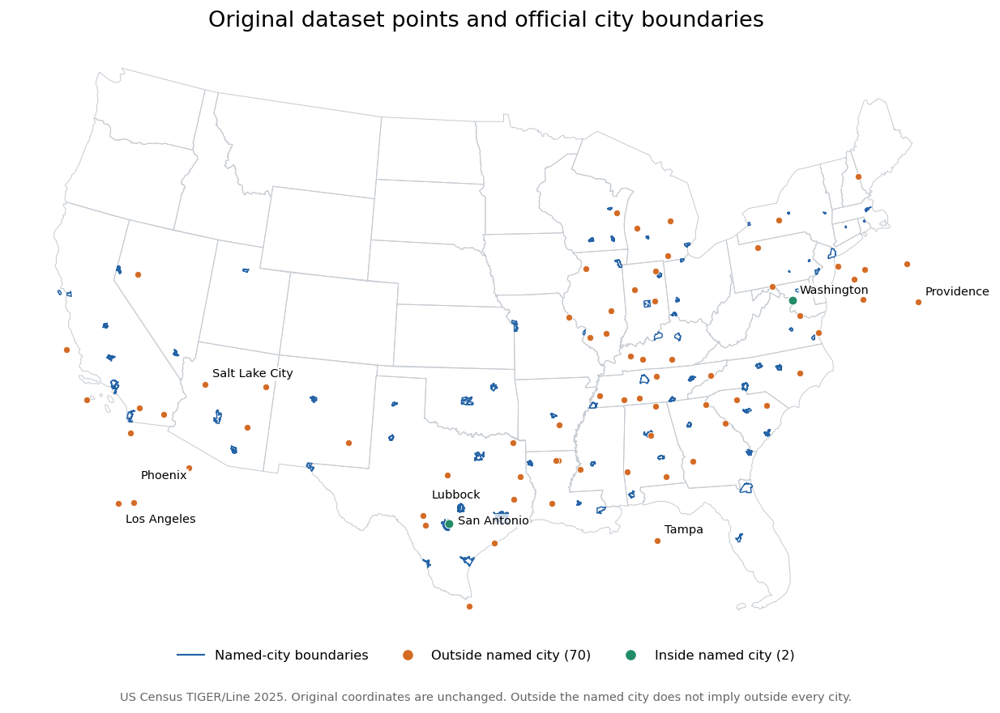

In [10]:
boundary_fig = city_boundary_map(
    boundary_audit, city_boundaries, data_dir / 'us-state-outlines-2025.geojson'
)
map_output = data_dir.parent / 'outputs' / 'city-boundary-audit.png'
map_output.parent.mkdir(exist_ok=True)
boundary_fig.savefig(map_output, dpi=150, facecolor='white')
plt.show()
plt.close(boundary_fig)


## Market index, quote signal and posted rate over time

The three panels show all loads, loads from Detroit, and loads to Detroit. Validation includes only known pickup and delivery cities. Market index and quote signal use the left axis; posted rate uses the right axis in USD and is available only in training. Dashed lines identify quote signal. The first panel shows daily means; Detroit panels show means across observed loads in the trailing 7 calendar days, calculated separately within each split. Missing values are excluded separately for each metric; empty windows remain blank. Faint Detroit dots show individual market indices. Corresponding axes share scales across panels.

In [11]:
market_samples = {'train': train_test_df, 'validation: known cities only': val_known}
market_summary = pd.DataFrame({
    name: df['market_index'].describe(percentiles=[.05, .25, .5, .75, .95])
    for name, df in market_samples.items()
}).T
market_summary['missing'] = [df['market_index'].isna().sum() for df in market_samples.values()]
market_summary['missing_pct'] = [df['market_index'].isna().mean() * 100
                                 for df in market_samples.values()]
display(market_summary.round(4))
signal_styles = {
    ('market_index', 'train'): ('#2463A6', 'solid'),
    ('market_index', 'validation: known cities only'): ('#238B63', 'solid'),
    ('quote_signal', 'train'): ('#DB7B2B', 'dash'),
    ('quote_signal', 'validation: known cities only'): ('#8B5CF6', 'dash'),
    ('posted_rate', 'train'): ('#C43B45', 'solid'),
}
fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, vertical_spacing=.085,
    specs=[[{'secondary_y': True}] for _ in range(3)],
    subplot_titles=['All loads: daily means', 'From Detroit: 7-day means',
                    'To Detroit: 7-day means'],
)
for row, city_column in [(1, None), (2, 'pickup'), (3, 'delivery')]:
    for name, df in market_samples.items():
        trips = df if city_column is None else df.loc[df[city_column].eq('Detroit')]
        calendar = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
        for metric in ['market_index', 'quote_signal', 'posted_rate']:
            if metric not in trips:
                continue
            daily_stats = trips.groupby('date')[metric].agg(['sum', 'count']).reindex(calendar)
            if row == 1:
                counts = daily_stats['count'].fillna(0)
                values = daily_stats['sum'] / counts.replace(0, np.nan)
            else:
                counts = daily_stats['count'].fillna(0).rolling(7, min_periods=1).sum()
                values = (daily_stats['sum'].fillna(0).rolling(7, min_periods=1).sum()
                          / counts.replace(0, np.nan))
            color, dash = signal_styles[(metric, name)]
            trace_name = f'{metric}: {name}'
            fig.add_trace(go.Scatter(
                x=calendar, y=values, mode='lines', name=trace_name,
                legendgroup=trace_name, showlegend=row == 1, connectgaps=False,
                line=dict(color=color, dash=dash, width=1.8),
                customdata=counts.to_numpy()[:, None],
                hovertemplate='%{x|%Y-%m-%d}<br>Mean: %{y:.4f}'
                              '<br>Observed loads: %{customdata[0]:.0f}<extra>' + trace_name + '</extra>',
            ), row=row, col=1, secondary_y=metric == 'posted_rate')
        if row > 1:
            valid_trips = trips.dropna(subset=['market_index'])
            fig.add_trace(go.Scatter(
                x=valid_trips['date'], y=valid_trips['market_index'], mode='markers',
                name=f'market_index: {name} (individual loads)',
                legendgroup=f'market_index: {name}', showlegend=False,
                marker=dict(color=signal_styles[('market_index', name)][0], size=4, opacity=.15),
                hovertemplate='%{x|%Y-%m-%d}<br>Market index: %{y:.4f}<extra>' + name + '</extra>',
            ), row=row, col=1, secondary_y=False)
    fig.update_yaxes(title_text='Market index / quote signal', row=row, col=1, secondary_y=False)
    fig.update_yaxes(title_text='Posted rate, USD', showgrid=False, tickformat=',.0f',
                     row=row, col=1, secondary_y=True)
    if row > 1:
        fig.update_yaxes(matches='y', row=row, col=1, secondary_y=False)
        fig.update_yaxes(matches='y2', row=row, col=1, secondary_y=True)
fig.add_vline(x=val_df['date'].min().timestamp() * 1000, line_dash='dot',
              line_color='#777777', line_width=1)
fig.update_xaxes(title_text='Date', row=3, col=1)
fig.update_layout(
    title='Market index, quote signal and posted rate over time', height=1150,
    legend=dict(orientation='h', y=-.09, x=0, title_text='', font=dict(size=10)),
    margin=dict(l=100, r=100, b=140), hovermode='x unified',
)
fig.show()

,count,mean,std,min,5%,25%,50%,75%,95%,max,missing,missing_pct
train,47626.0,1.0834,0.1681,0.6764,0.8363,0.9497,1.0558,1.2196,1.3660,1.4678,374,0.7792
validation: known cities only,10337.0,0.9272,0.0743,0.7236,0.8144,0.8641,0.9232,0.9930,1.0411,1.0990,216,2.0468


## Quote signal vs. posted rate

Test the hypothesis `posted_rate ≈ quote_signal * distance`. All metrics use every training row. A chronological comparison fits a constant rate per mile using January–August only and evaluates both formulas on September–October. Scatter plots use a fixed sample of up to 12,000 rows for readability and logarithmic axes; no outliers are removed. Predictive association cannot establish whether the signal was available before the target.

In [12]:
quote_check = train_test_df.copy()
quote_check['quote_total'] = quote_check['quote_signal'] * quote_check['distance']
quote_check['actual_rate_per_mile'] = quote_check['posted_rate'] / quote_check['distance']
quote_check['relative_error_pct'] = (
    (quote_check['quote_total'] - quote_check['posted_rate']) / quote_check['posted_rate'] * 100
)
error = quote_check['quote_total'] - quote_check['posted_rate']
display(pd.Series({
    'corr_quote_total_vs_posted_rate': quote_check['quote_total'].corr(quote_check['posted_rate']),
    'corr_signal_vs_actual_rate_per_mile': quote_check['quote_signal'].corr(quote_check['actual_rate_per_mile']),
    'spearman_signal_vs_actual_rate_per_mile': quote_check['quote_signal'].rank().corr(
        quote_check['actual_rate_per_mile'].rank()),
    'MAE_USD': error.abs().mean(), 'RMSE_USD': np.sqrt(error.pow(2).mean()),
    'MAPE_pct': quote_check['relative_error_pct'].abs().mean(),
    'within_1pct_of_target_pct': quote_check['relative_error_pct'].abs().le(1).mean() * 100,
    'within_5pct_of_target_pct': quote_check['relative_error_pct'].abs().le(5).mean() * 100,
}).round(4).to_frame('value'))

fit_rows = quote_check['date'].lt('2025-09-01')
constant_rate = quote_check.loc[fit_rows, 'actual_rate_per_mile'].median()
evaluation = quote_check.loc[~fit_rows]
comparison = []
for name, prediction in {
    'quote_signal * distance': evaluation['quote_total'],
    'Jan-Aug median rate per mile * distance': evaluation['distance'] * constant_rate,
}.items():
    err = prediction - evaluation['posted_rate']
    comparison.append({'formula': name, 'evaluation_rows': len(evaluation),
                       'MAE_USD': err.abs().mean(), 'RMSE_USD': np.sqrt(err.pow(2).mean()),
                       'MAPE_pct': (err / evaluation['posted_rate']).abs().mean() * 100})
display(pd.DataFrame(comparison).set_index('formula').round(3))
display(quote_check.loc[error.abs().nlargest(10).index,
                       ['load_id', 'date', 'distance', 'quote_signal', 'posted_rate',
                        'quote_total', 'relative_error_pct']].round(3))

,value
corr_quote_total_vs_posted_rate,0.8987
corr_signal_vs_actual_rate_per_mile,0.0493
spearman_signal_vs_actual_rate_per_mile,0.0911
MAE_USD,232.2582
RMSE_USD,674.5716
MAPE_pct,11.3748
within_1pct_of_target_pct,34.5667
within_5pct_of_target_pct,58.1021


,evaluation_rows,MAE_USD,RMSE_USD,MAPE_pct
formula,,,,
quote_signal * distance,9523,246.022,711.800,12.110
Jan-Aug median rate per mile * distance,9523,256.953,684.248,11.631


,load_id,date,distance,quote_signal,posted_rate,quote_total,relative_error_pct
12184,TR-012185,2025-03-19,2829.8,1.832,25533.00,5183.854,-79.697
1466,TR-001467,2025-01-10,2786.0,1.854,24140.21,5164.408,-78.607
26235,TR-026236,2025-06-15,2552.5,1.813,23580.42,4627.402,-80.376
37764,TR-037765,2025-08-27,2810.9,2.163,24294.98,6079.527,-74.976
28219,TR-028220,2025-06-27,2423.3,1.971,22755.66,4776.615,-79.009
17371,TR-017372,2025-04-20,2777.6,2.156,23662.71,5988.533,-74.692
3353,TR-003354,2025-01-22,2527.9,2.073,22534.65,5241.398,-76.741
40096,TR-040097,2025-09-11,1760.3,2.288,20132.37,4026.739,-79.999
40171,TR-040172,2025-09-11,2283.4,1.936,20361.89,4421.690,-78.284
31259,TR-031260,2025-07-16,1747.7,1.804,19042.39,3152.956,-83.442


In [13]:
quote_plot = quote_check.sample(min(12_000, len(quote_check)), random_state=42)
fig = make_subplots(rows=1, cols=2, horizontal_spacing=.14,
                    subplot_titles=['Total rate vs. quote-derived total',
                                    'Actual rate per mile vs. quote signal'])
for col, xcol, ycol in [(1, 'quote_total', 'posted_rate'),
                         (2, 'quote_signal', 'actual_rate_per_mile')]:
    fig.add_trace(go.Scattergl(
        x=quote_plot[xcol], y=quote_plot[ycol], mode='markers',
        marker=dict(color=colors['train'], size=4, opacity=.25), showlegend=False,
        customdata=quote_plot[['load_id', 'distance']].to_numpy(),
        hovertemplate='%{customdata[0]}<br>Distance: %{customdata[1]:.1f} miles'
                      '<br>x: %{x:.3f}<br>y: %{y:.3f}<extra></extra>',
    ), row=1, col=col)
    low = float(min(quote_check[xcol].min(), quote_check[ycol].min()))
    high = float(max(quote_check[xcol].max(), quote_check[ycol].max()))
    fig.add_trace(go.Scatter(x=[low, high], y=[low, high], mode='lines', name='Exact equality',
                             legendgroup='equality', showlegend=col == 1,
                             line=dict(color='#555555', dash='dash', width=1)), row=1, col=col)
    fig.update_xaxes(type='log', title_text='Quote signal * distance, USD' if col == 1
                     else 'Quote signal', row=1, col=col)
    fig.update_yaxes(type='log', title_text='Posted rate, USD' if col == 1
                     else 'Posted rate / distance, USD per mile', row=1, col=col)
fig.update_layout(title='Quote signal relationship with the target (12,000 sampled loads)',
                  height=500, legend=dict(orientation='h', y=-.25, x=0), margin=dict(b=100))
fig.show()